# Lab 05: Predict Late Deliveries
QuickBite — reproducible model evaluation. All model and threshold decisions are based on training folds. The saved test report was produced once by `python -m latedeliveries.train`. This notebook displays that frozen result without refitting or retuning.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from latedeliveries.data import make_orders

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
metrics = json.loads((ROOT / "reports/metrics.json").read_text(encoding="utf-8"))
cv = pd.read_csv(ROOT / "reports/cv_results.csv")
costs = pd.DataFrame(
    json.loads((ROOT / "reports/threshold_costs.json").read_text(encoding="utf-8"))
)

## Late-order prevalence

In [2]:
orders = make_orders()
print(f"Late orders: {orders.late.sum()} / {len(orders)} ({orders.late.mean():.1%})")

Late orders: 468 / 3000 (15.6%)


## Five-fold training-only model comparison

In [3]:
display(cv.round(3))

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Dummy,0.844,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000
1,Logistic,0.857,0.007,0.627,0.072,0.213,0.049,0.315,0.059,0.775,0.038
2,Balanced logistic,0.739,0.022,0.332,0.032,0.661,0.046,0.442,0.038,0.775,0.038
3,Decision tree,0.848,0.008,0.540,0.064,0.248,0.027,0.336,0.017,0.724,0.021
4,Random forest,0.860,0.002,0.705,0.062,0.179,0.021,0.284,0.021,0.768,0.042


## Training-only cost versus threshold

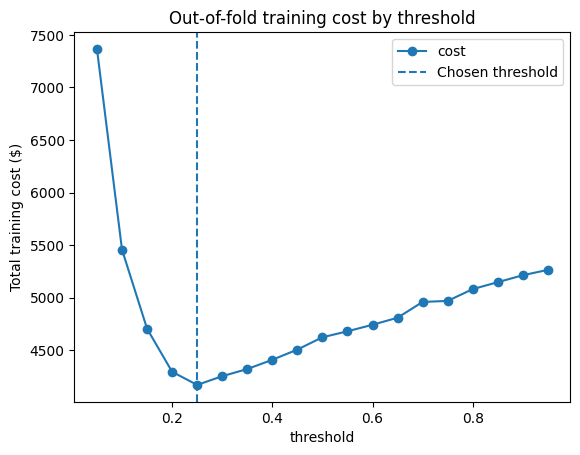

In [4]:
ax = costs.plot(
    x="threshold",
    y="cost",
    marker="o",
    legend=False,
    title="Out-of-fold training cost by threshold",
)
ax.axvline(metrics["threshold"], linestyle="--", label="Chosen threshold")
ax.set_ylabel("Total training cost ($)")
ax.legend()
plt.show()

## Frozen held-out test confusion matrix and policy costs

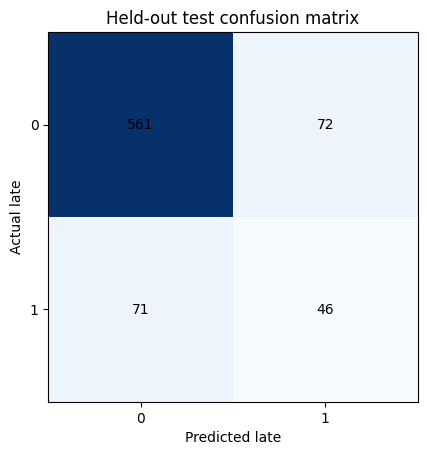

flag_nobody       1755
flag_everybody    3000
model             1537
Name: Cost ($), dtype: int64
{'accuracy': 0.8093333333333333, 'precision': 0.3898305084745763, 'recall': 0.39316239316239315, 'f1': 0.39148936170212767, 'roc_auc': 0.7476742144988591}


In [5]:
cm = np.asarray(metrics["confusion_matrix"])
fig, ax = plt.subplots()
ax.imshow(cm, cmap="Blues")
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xlabel("Predicted late")
ax.set_ylabel("Actual late")
ax.set_title("Held-out test confusion matrix")
plt.show()
print(pd.Series(metrics["costs"], name="Cost ($)"))
print(metrics["metrics"])

## Recommendation (under 200 words)
Use this model as a **limited simulated pilot**, not an autonomous real-world voucher system. On the held-out test, it costs $1537 versus $1755 for flagging nobody, saving $218. The threshold of 0.25 minimizes the specified $4 voucher plus $15 missed-late cost on **training-only out-of-fold predictions**, avoiding test-set threshold tuning. We excluded order ID (identifier), preparation time and customer rating (future information), and courier vehicle and experience (not guaranteed known when ordering). A key limitation is that all orders are simulated and the costs assume every voucher fully offsets customer dissatisfaction. Validate feature availability, real costs, and calibration on actual orders before deployment.